In [1]:

import pandas as pd

# Membaca dataset
df = pd.read_csv('nasabah_raw.csv')
df_eksternal = pd.read_csv('data_kredit_eksternal.csv')

# 1. Memeriksa dimensi awal dataset
print("Dimensi Awal Dataset:")
print(df.shape)

# 2. Memeriksa informasi tipe data
print("\nInformasi Dataset:")
df.info()

# 3. Menghitung jumlah data duplikat
print("\nJumlah Data Duplikat:")
print(df.duplicated().sum())

# 4. Menampilkan sampel data duplikat
print("\nSampel Data Duplikat:")
print(df[df.duplicated(keep=False)].head(10))

# 5. Menghapus seluruh data duplikat
df = df.drop_duplicates()

# 6. Memeriksa jumlah baris setelah penghapusan
print("\nDimensi Setelah Menghapus Duplikat:")
print(df.shape)


Dimensi Awal Dataset:
(1045, 9)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1045 entries, 0 to 1044
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ID_Pelanggan            1045 non-null   object 
 1   Usia                    1045 non-null   float64
 2   Pendapatan_Bulanan      983 non-null    float64
 3   Skor_Kredit             1045 non-null   float64
 4   Lama_Bekerja_Thn        1003 non-null   float64
 5   Status_Pernikahan       1045 non-null   object 
 6   Tingkat_Pendidikan      1008 non-null   object 
 7   Status_Default          1045 non-null   int64  
 8   Pendapatan_Tahunan_Est  983 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 73.6+ KB

Jumlah Data Duplikat:
45

Sampel Data Duplikat:
    ID_Pelanggan  Usia  Pendapatan_Bulanan  Skor_Kredit  Lama_Bekerja_Thn  \
59     CUST-1060  53.0          14765000.0        461.0               

In [2]:

# 1. Memeriksa nilai unik sebelum dibersihkan
print("Status Pernikahan Sebelum Dibersihkan:")
print(df['Status_Pernikahan'].unique())

# 2. Membersihkan spasi dan format huruf
df['Status_Pernikahan'] = (
    df['Status_Pernikahan']
    .str.strip()
    .str.title()
)

# 3. Memeriksa hasil setelah dibersihkan
print("\nStatus Pernikahan Setelah Dibersihkan:")
print(df['Status_Pernikahan'].unique())


Status Pernikahan Sebelum Dibersihkan:
['Menikah' 'Single' 'single' 'Cerai' ' MENIKAH ']

Status Pernikahan Setelah Dibersihkan:
['Menikah' 'Single' 'Cerai']


In [3]:

import numpy as np

# Memeriksa usia yang tidak valid
print("Usia Minimum:", df['Usia'].min())
print("Usia Maksimum:", df['Usia'].max())

# Menghitung jumlah usia tidak valid
usia_tidak_valid = (
    (df['Usia'] < 17) |
    (df['Usia'] > 100)
)

print("\nJumlah Usia Tidak Valid:")
print(usia_tidak_valid.sum())

# Mengubah usia tidak valid menjadi NaN
df.loc[usia_tidak_valid, 'Usia'] = np.nan

# Memeriksa hasil setelah perbaikan
print("\nJumlah Missing Value pada Usia:")
print(df['Usia'].isnull().sum())

print("\nStatistik Usia Setelah Dibersihkan:")
print(df['Usia'].describe())


Usia Minimum: -5.0
Usia Maksimum: 350.0

Jumlah Usia Tidak Valid:
35

Jumlah Missing Value pada Usia:
35

Statistik Usia Setelah Dibersihkan:
count    965.000000
mean      40.048705
std       11.787130
min       20.000000
25%       30.000000
50%       41.000000
75%       50.000000
max       59.000000
Name: Usia, dtype: float64


In [4]:

# C. INTEGRASI DATA

# 1. Menggabungkan dataset menggunakan Left Join
df = pd.merge(
    df,
    df_eksternal,
    on='ID_Pelanggan',
    how='left'
)

# 2. Menampilkan dimensi dataset setelah penggabungan
print("Dimensi Dataset Setelah Merge:")
print(df.shape)

# 3. Menampilkan beberapa data hasil penggabungan
print("\nSampel Data Setelah Merge:")
display(df.head(10))

# 4. Memeriksa kolom hasil penggabungan
print("\nDaftar Kolom Dataset:")
print(df.columns.tolist())


Dimensi Dataset Setelah Merge:
(1000, 11)

Sampel Data Setelah Merge:


,ID_Pelanggan,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Status_Pernikahan,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit
0,CUST-1001,58.0,10118000.0,542.0,13.0,Menikah,Magister,0,121416000.0,Tidak,5.0
1,CUST-1002,48.0,10514000.0,331.0,20.0,Menikah,Sarjana,0,126168000.0,Tidak,3.0
2,CUST-1003,34.0,13257000.0,690.0,22.0,Menikah,Magister,0,159084000.0,Tidak,5.0
3,CUST-1004,27.0,10832000.0,576.0,7.0,Menikah,Sarjana,0,129984000.0,Ya,6.0
4,CUST-1005,NaN,8295000.0,831.0,15.0,Single,SMA,0,99540000.0,Ya,4.0
5,CUST-1006,58.0,8702000.0,453.0,23.0,Single,SMA,0,104424000.0,Tidak,2.0
6,CUST-1007,38.0,13613000.0,682.0,14.0,Menikah,Sarjana,0,163356000.0,Tidak,2.0
7,CUST-1008,42.0,7924000.0,367.0,23.0,Menikah,SMA,0,95088000.0,Tidak,4.0
8,CUST-1009,30.0,16191000.0,513.0,19.0,Cerai,SMA,0,194292000.0,Tidak,6.0
9,CUST-1010,30.0,9929000.0,675.0,22.0,Menikah,Magister,0,119148000.0,Tidak,4.0



Daftar Kolom Dataset:
['ID_Pelanggan', 'Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Status_Pernikahan', 'Tingkat_Pendidikan', 'Status_Default', 'Pendapatan_Tahunan_Est', 'Pernah_Gagal_Bayar_Lain', 'Jumlah_Kartu_Kredit']


In [5]:

# D. PENANGANAN MISSING VALUES

# Menghitung jumlah missing value setiap kolom
jumlah_missing = df.isnull().sum()

# Menghitung persentase missing value setiap kolom
persentase_missing = (df.isnull().mean() * 100).round(2)

# Membuat tabel missing values
tabel_missing = pd.DataFrame({
    'Jumlah Missing': jumlah_missing,
    'Persentase (%)': persentase_missing
})

print("Tabel Missing Values:")
display(tabel_missing)


Tabel Missing Values:


,Jumlah Missing,Persentase (%)
ID_Pelanggan,0,0.0
Usia,35,3.5
Pendapatan_Bulanan,60,6.0
Skor_Kredit,0,0.0
Lama_Bekerja_Thn,40,4.0
Status_Pernikahan,0,0.0
Tingkat_Pendidikan,35,3.5
Status_Default,0,0.0
Pendapatan_Tahunan_Est,60,6.0
Pernah_Gagal_Bayar_Lain,150,15.0


In [6]:

# 1. Mengisi kolom numerik dengan median
kolom_numerik = [
    'Usia',
    'Pendapatan_Bulanan',
    'Lama_Bekerja_Thn',
    'Pendapatan_Tahunan_Est'
]

for kolom in kolom_numerik:
    df[kolom] = df[kolom].fillna(df[kolom].median())

# 2. Mengisi Jumlah_Kartu_Kredit dengan 0
df['Jumlah_Kartu_Kredit'] = df['Jumlah_Kartu_Kredit'].fillna(0)

# 3. Mengisi kolom kategorikal dengan modus
kolom_kategorikal = [
    'Tingkat_Pendidikan',
    'Pernah_Gagal_Bayar_Lain'
]

for kolom in kolom_kategorikal:
    df[kolom] = df[kolom].fillna(df[kolom].mode()[0])

# 4. Memeriksa kembali missing values
print("Jumlah Missing Values Setelah Penanganan:")
print(df.isnull().sum())

# 5. Memastikan tidak ada missing value
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Jumlah Missing Values Setelah Penanganan:
ID_Pelanggan               0
Usia                       0
Pendapatan_Bulanan         0
Skor_Kredit                0
Lama_Bekerja_Thn           0
Status_Pernikahan          0
Tingkat_Pendidikan         0
Status_Default             0
Pendapatan_Tahunan_Est     0
Pernah_Gagal_Bayar_Lain    0
Jumlah_Kartu_Kredit        0
dtype: int64

Total Missing Values:
0


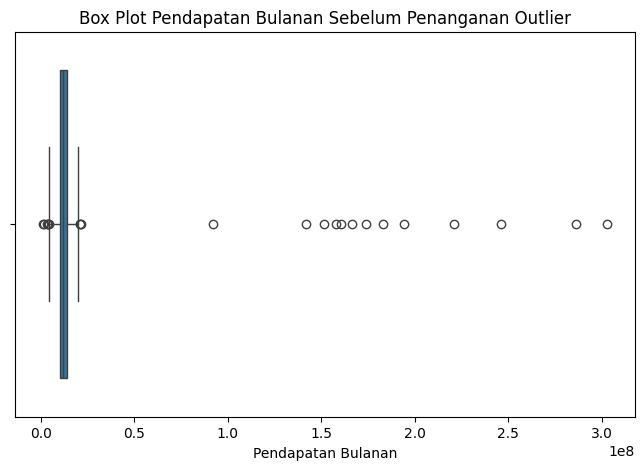

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Membuat Box Plot sebelum penanganan outlier
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Pendapatan_Bulanan'])

plt.title('Box Plot Pendapatan Bulanan Sebelum Penanganan Outlier')
plt.xlabel('Pendapatan Bulanan')
plt.show()


In [8]:

# Menghitung kuartil pertama dan ketiga
Q1 = df['Pendapatan_Bulanan'].quantile(0.25)
Q3 = df['Pendapatan_Bulanan'].quantile(0.75)

# Menghitung IQR
IQR = Q3 - Q1

# Menghitung batas bawah dan batas atas
batas_bawah = Q1 - (1.5 * IQR)
batas_atas = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas Bawah:", batas_bawah)
print("Batas Atas:", batas_atas)

# Menghitung jumlah outlier
jumlah_outlier = (
    (df['Pendapatan_Bulanan'] < batas_bawah) |
    (df['Pendapatan_Bulanan'] > batas_atas)
).sum()

print("\nJumlah Outlier:", jumlah_outlier)


Q1: 10192000.0
Q3: 14100250.0
IQR: 3908250.0
Batas Bawah: 4329625.0
Batas Atas: 19962625.0

Jumlah Outlier: 22


Outlier berhasil dibatasi.


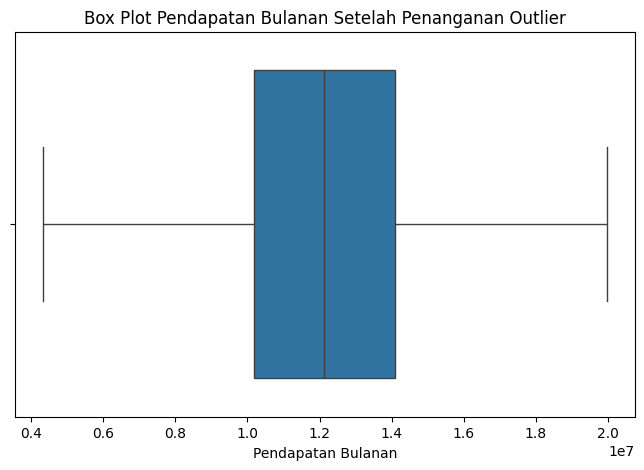

In [9]:

# Membatasi nilai ekstrem menggunakan metode IQR
df['Pendapatan_Bulanan'] = df['Pendapatan_Bulanan'].clip(
    lower=batas_bawah,
    upper=batas_atas
)

print("Outlier berhasil dibatasi.")

# Membuat Box Plot setelah penanganan outlier
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Pendapatan_Bulanan'])

plt.title('Box Plot Pendapatan Bulanan Setelah Penanganan Outlier')
plt.xlabel('Pendapatan Bulanan')
plt.show()


In [10]:

# 1. Ordinal Encoding
mapping_pendidikan = {
    'SMA': 1,
    'Sarjana': 2,
    'Magister': 3
}

df['Tingkat_Pendidikan'] = df['Tingkat_Pendidikan'].map(
    mapping_pendidikan
)

print("Ordinal Encoding berhasil:")
print(df['Tingkat_Pendidikan'].value_counts().sort_index())


Ordinal Encoding berhasil:
Tingkat_Pendidikan
1    297
2    509
3    194
Name: count, dtype: int64


In [11]:

# 2. Binary Mapping
mapping_gagal_bayar = {
    'Tidak': 0,
    'Ya': 1
}

df['Pernah_Gagal_Bayar_Lain'] = df[
    'Pernah_Gagal_Bayar_Lain'
].map(mapping_gagal_bayar)

print("Binary Mapping berhasil:")
print(df['Pernah_Gagal_Bayar_Lain'].value_counts())


Binary Mapping berhasil:
Pernah_Gagal_Bayar_Lain
0    881
1    119
Name: count, dtype: int64


In [12]:

# 3. One-Hot Encoding
df = pd.get_dummies(
    df,
    columns=['Status_Pernikahan'],
    drop_first=True,
    dtype=int
)

print("One-Hot Encoding berhasil.")
print(df.head())


One-Hot Encoding berhasil.
  ID_Pelanggan  Usia  Pendapatan_Bulanan  Skor_Kredit  Lama_Bekerja_Thn  \
0    CUST-1001  58.0          10118000.0        542.0              13.0   
1    CUST-1002  48.0          10514000.0        331.0              20.0   
2    CUST-1003  34.0          13257000.0        690.0              22.0   
3    CUST-1004  27.0          10832000.0        576.0               7.0   
4    CUST-1005  41.0           8295000.0        831.0              15.0   

   Tingkat_Pendidikan  Status_Default  Pendapatan_Tahunan_Est  \
0                   3               0             121416000.0   
1                   2               0             126168000.0   
2                   3               0             159084000.0   
3                   2               0             129984000.0   
4                   1               0              99540000.0   

   Pernah_Gagal_Bayar_Lain  Jumlah_Kartu_Kredit  Status_Pernikahan_Menikah  \
0                        0                  5.0      

In [13]:

# 4. Menghapus kolom identifier
df = df.drop(columns=['ID_Pelanggan'])

# Memeriksa hasil akhir encoding
print("Kolom Setelah Encoding:")
print(df.columns.tolist())

print("\nDimensi Dataset:")
print(df.shape)

print("\nLima Data Pertama:")
display(df.head())

# Memeriksa tipe data
print("\nInformasi Dataset:")
df.info()


Kolom Setelah Encoding:
['Usia', 'Pendapatan_Bulanan', 'Skor_Kredit', 'Lama_Bekerja_Thn', 'Tingkat_Pendidikan', 'Status_Default', 'Pendapatan_Tahunan_Est', 'Pernah_Gagal_Bayar_Lain', 'Jumlah_Kartu_Kredit', 'Status_Pernikahan_Menikah', 'Status_Pernikahan_Single']

Dimensi Dataset:
(1000, 11)

Lima Data Pertama:


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Status_Default,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.0,10118000.0,542.0,13.0,3,0,121416000.0,0,5.0,1,0
1,48.0,10514000.0,331.0,20.0,2,0,126168000.0,0,3.0,1,0
2,34.0,13257000.0,690.0,22.0,3,0,159084000.0,0,5.0,1,0
3,27.0,10832000.0,576.0,7.0,2,0,129984000.0,1,6.0,1,0
4,41.0,8295000.0,831.0,15.0,1,0,99540000.0,1,4.0,0,1



Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Usia                       1000 non-null   float64
 1   Pendapatan_Bulanan         1000 non-null   float64
 2   Skor_Kredit                1000 non-null   float64
 3   Lama_Bekerja_Thn           1000 non-null   float64
 4   Tingkat_Pendidikan         1000 non-null   int64  
 5   Status_Default             1000 non-null   int64  
 6   Pendapatan_Tahunan_Est     1000 non-null   float64
 7   Pernah_Gagal_Bayar_Lain    1000 non-null   int64  
 8   Jumlah_Kartu_Kredit        1000 non-null   float64
 9   Status_Pernikahan_Menikah  1000 non-null   int64  
 10  Status_Pernikahan_Single   1000 non-null   int64  
dtypes: float64(6), int64(5)
memory usage: 86.1 KB


In [14]:

# G. FEATURE SCALING

# 1. Memisahkan fitur prediktor (X) dan target (y)
X = df.drop(columns=['Status_Default'])
y = df['Status_Default']

print("Dimensi Fitur X:", X.shape)
print("Dimensi Target y:", y.shape)

# Memeriksa data
print("\nFitur Prediktor:")
display(X.head())

print("\nTarget:")
display(y.head())


Dimensi Fitur X: (1000, 10)
Dimensi Target y: (1000,)

Fitur Prediktor:


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single
0,58.0,10118000.0,542.0,13.0,3,121416000.0,0,5.0,1,0
1,48.0,10514000.0,331.0,20.0,2,126168000.0,0,3.0,1,0
2,34.0,13257000.0,690.0,22.0,3,159084000.0,0,5.0,1,0
3,27.0,10832000.0,576.0,7.0,2,129984000.0,1,6.0,1,0
4,41.0,8295000.0,831.0,15.0,1,99540000.0,1,4.0,0,1



Target:


,Status_Default
0,0
1,0
2,0
3,0
4,0


In [15]:

# 2. Statistik sebelum standarisasi
fitur_contoh = [
    'Usia',
    'Pendapatan_Bulanan',
    'Skor_Kredit'
]

print("Statistik Sebelum Standardization:")
display(X[fitur_contoh].describe())


Statistik Sebelum Standardization:


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,1000.000000,1.000000e+03,1000.000000
mean,40.082000,1.212750e+07,580.507000
std,11.580128,3.062611e+06,158.990729
min,20.000000,4.329625e+06,300.000000
25%,30.000000,1.019200e+07,440.750000
50%,41.000000,1.213200e+07,579.000000
75%,50.000000,1.410025e+07,722.250000
max,59.000000,1.996262e+07,849.000000


In [16]:

from sklearn.preprocessing import StandardScaler

# 3. Melakukan standarisasi seluruh fitur numerik
scaler = StandardScaler()

kolom_numerik = X.select_dtypes(include=['number']).columns

X_scaled = X.copy()

X_scaled[kolom_numerik] = scaler.fit_transform(
    X[kolom_numerik]
)

print("Standardization berhasil dilakukan.")


Standardization berhasil dilakukan.


In [17]:

# 4. Statistik setelah standarisasi
print("Statistik Setelah Standardization:")
display(X_scaled[fitur_contoh].describe())

# Memeriksa mean dan standar deviasi
print("\nRata-rata Setelah Standardization:")
print(X_scaled[kolom_numerik].mean())

print("\nStandar Deviasi Setelah Standardization:")
print(X_scaled[kolom_numerik].std())


Statistik Setelah Standardization:


,Usia,Pendapatan_Bulanan,Skor_Kredit
count,1.000000e+03,1.000000e+03,1.000000e+03
mean,-7.105427e-17,3.552714e-18,3.232969e-16
std,1.000500e+00,1.000500e+00,1.000500e+00
min,-1.735045e+00,-2.547425e+00,-1.765181e+00
25%,-8.710650e-01,-6.322922e-01,-8.794659e-01
50%,7.931340e-02,1.471131e-03,-9.483283e-03
75%,8.568957e-01,6.444632e-01,8.919635e-01
max,1.634478e+00,2.559596e+00,1.689579e+00



Rata-rata Setelah Standardization:
Usia                        -7.105427e-17
Pendapatan_Bulanan           3.552714e-18
Skor_Kredit                  3.232969e-16
Lama_Bekerja_Thn            -5.684342e-17
Tingkat_Pendidikan          -5.506706e-17
Pendapatan_Tahunan_Est       1.065814e-16
Pernah_Gagal_Bayar_Lain     -1.776357e-17
Jumlah_Kartu_Kredit          0.000000e+00
Status_Pernikahan_Menikah   -7.016610e-17
Status_Pernikahan_Single     3.019807e-17
dtype: float64

Standar Deviasi Setelah Standardization:
Usia                         1.0005
Pendapatan_Bulanan           1.0005
Skor_Kredit                  1.0005
Lama_Bekerja_Thn             1.0005
Tingkat_Pendidikan           1.0005
Pendapatan_Tahunan_Est       1.0005
Pernah_Gagal_Bayar_Lain      1.0005
Jumlah_Kartu_Kredit          1.0005
Status_Pernikahan_Menikah    1.0005
Status_Pernikahan_Single     1.0005
dtype: float64


In [18]:

# 5. Menggabungkan fitur dan target
df_final = X_scaled.copy()
df_final['Status_Default'] = y

# 6. Menyimpan dataset ke CSV
df_final.to_csv(
    'clean_nasabah_final.csv',
    index=False
)

print("Dataset berhasil disimpan!")
print("Nama File: clean_nasabah_final.csv")

print("\nDimensi Dataset Final:")
print(df_final.shape)

print("\nLima Data Pertama:")
display(df_final.head())

# Memeriksa missing values terakhir
print("\nTotal Missing Values:")
print(df_final.isnull().sum().sum())


Dataset berhasil disimpan!
Nama File: clean_nasabah_final.csv

Dimensi Dataset Final:
(1000, 11)

Lima Data Pertama:


,Usia,Pendapatan_Bulanan,Skor_Kredit,Lama_Bekerja_Thn,Tingkat_Pendidikan,Pendapatan_Tahunan_Est,Pernah_Gagal_Bayar_Lain,Jumlah_Kartu_Kredit,Status_Pernikahan_Menikah,Status_Pernikahan_Single,Status_Default
0,1.548080,-0.656467,-0.242318,0.007777,1.591395,-0.196932,-0.367524,1.204949,0.924818,-0.781221,0
1,0.684100,-0.527101,-1.570103,1.054639,0.148607,-0.178474,-0.367524,0.255423,0.924818,-0.781221,0
2,-0.525473,0.368989,0.689020,1.353742,1.591395,-0.050615,-0.367524,1.204949,0.924818,-0.781221,0
3,-1.130259,-0.423216,-0.028362,-0.889534,0.148607,-0.163651,2.720912,1.679712,0.924818,-0.781221,0
4,0.079313,-1.252008,1.576308,0.306880,-1.294181,-0.281907,2.720912,0.730186,-1.081294,1.280048,0



Total Missing Values:
0
